# E05 — Coupling dynamic topography to preserved sediment flux on every continent


**Cluster E: Mantle dynamics + dynamic topography.**
**Extract a plate-frame dynamic-topography time series for each continent and plot it against the preserved sediment record of the same continent. Adapted from the online supplement of Dhungana & Flament (2026), *The deep Earth origin of the Great Unconformity*, this notebook lets you ask whether long-term uplift and subsidence driven by the mantle control how much sediment each continent has preserved.**

## What this notebook produces

Ronov's classic compilation, as tabulated in the supplementary data of Keller et al. (2019), gives a per-continent record of preserved sediment volume binned by age — how much sediment from each continent we still have in the rock record, time-series style. Dynamic topography is, by hypothesis, one of the drivers of that signal: continents that are located on top of upwelling mantle uplift, shed sediment to the global ocean, and lose preserved record (no accommodation space); continents that are located on downwelling mantle subside and accumulate sediment. The two records are different observational windows on the same process.

This notebook lays the two on top of each other. For North America, South America, Africa, Eurasia and Australia we compute the plate-frame DT history (mean DT across the continent's interior as a function of time) and plot it against that continent's preserved-sediment rate. Where the two co-vary the DT hypothesis survives the test on that continent; where they don't, something else dominates.

The result is one figure per continent with two y-axes: DT in black on the left, the preserved-sediment rate in orange on the right, on a common age axis from 0 to 920 Ma.

**Audience**: postgrad.
**Difficulty**: ★★☆.

## Learning objectives

- Extract a plate-frame time-series of a global raster across the area of a moving continent.
- Combine two independent observational records of the same Earth-system process and reason about their co-variation.
- Draw two quantities with different units in one pyGMT figure, using two basemaps that share a projection (one y-axis on each side).

## Prerequisites and runtime

- Plate model: Cao 2024.
- Mantle / DT: `zenodo_data/dynamic_topography_Dhungana/` — Santosh Dhungana's per-(continent, age) dynamic-topography `.nc` files.
- Sediment record: `data/Keller_PNAS_2018/Keller_PNAS_2018_pnas.1804350116.sd02.xls` (Ronov per-continent sediment volumes per age interval, Dataset S2 of Keller et al., 2019; bundled with the suite).
- Python: `gplately`, `pygmt`, `pygplates`, `xarray`, `numpy`, `pandas`, and `xlrd` (or `python-calamine`) to read the `.xls` file.
- Runtime: \~1 minute.


## Data availability — how to get the bundled netCDFs

This notebook reads time-dependent mantle / dynamic-topography
netCDFs from Santosh Dhungana's online supplement to
**Dhungana & Flament (2026) — *The deep Earth origin of the Great
Unconformity***, *Nature* 659, 106–112 (https://doi.org/10.1038/s41586-026-11156-5). The dataset is hosted in his GitHub repository, which
uses Git LFS for the binary files:

> https://github.com/santosh-dhungana/Dynamic-Topography-and-Great-Unconformity

The fields used by this notebook are too large to bundle into the
tutorial suite (multi-100 MB per cube, with sibling files totalling
GB-scale). To run E05 end-to-end, clone Santosh's repo (https://github.com/santosh-dhungana/Dynamic-Topography-and-Great-Unconformity)
with Git LFS:

```bash
# one-time install (macOS: brew install git-lfs; Linux: apt install git-lfs)
git lfs install

# then clone normally — LFS pull is automatic
git clone https://github.com/santosh-dhungana/Dynamic-Topography-and-Great-Unconformity

# then move the clone into zenodo_data/ under the name the notebook expects
mv Dynamic-Topography-and-Great-Unconformity zenodo_data/dynamic_topography_Dhungana
```

or leave the clone where it is and set `SANTOSH_REPO` in the CONFIGURATION cell below
(or the `ZENODO_SANTOSH_DIR` environment variable) to its local path. The specific files this notebook reads are listed
in the cell after configuration, so you can confirm they exist before
running the rest of the workflow:


- `DTvsSediment/{model}/PlateFrameGrid_{continent}/*.nc` — per-continent plate-frame DT
  time series per continent (this notebook uses AFR, AMZ, AUS, EAS and LAU)
- `DTvsSediment/{model}_{continent}_{plateID}.gpml` — paleo-continent block geometries

The sediment record is bundled with the tutorial suite: `data/Keller_PNAS_2018/Keller_PNAS_2018_pnas.1804350116.sd02.xls`
is Dataset S2 of Keller et al. (2019), https://doi.org/10.1073/pnas.1804350116, with the Ronov
per-continent sediment volumes per age interval (columns `t_age`, `b_age`, `Ronov_NAm`,
`Ronov_SAm`, `Ronov_Afr`, `Ronov_Eur`, `Ronov_Aus`, ...). Dividing each volume by the length of
its interval gives the preserved-sediment rate in km³ per year, as in Fig. S1 of Keller et al. (2019).


## Upstream data citations

- **Mantle-flow simulations** used by Dhungana & Flament rest on Müller
  et al.'s (2022) tectonic-rules-based mantle reference frame:
  https://doi.org/10.5194/se-13-1127-2022
- **Deep-time plate kinematics** used by the M2020 / Merdith
  reconstructions are from Merdith et al. (2021):
  https://doi.org/10.1016/j.earscirev.2020.103477
- **Late-Precambrian to Phanerozoic boundary kinematics** used by Cao
  2024 are from Cao et al. (2024): https://doi.org/10.1016/j.gsf.2024.101922

When you publish a result derived from this notebook, please cite the
Dhungana & Flament (2026) paper for the dataset, Keller et al. (2019) for the
sediment record, the upstream Müller /
Merdith / Cao paper for whichever rotation model you used, and the
GPlately + pyGMT papers (Mather et al.  (https://github.com/brmather/SeafloorAnomalies)2024; Tian et al. 2024)
for the software stack.


In [1]:
# Defensive cwd fix: when Jupyter runs this notebook from Notebooks/, the
# `data/...` relative paths used below would not resolve. Step up to the
# suite root once so every `data/...` literal in the rest of the notebook
# finds its file. Idempotent — only runs if `../data` exists and `./data`
# doesn't.
import os as _os
from pathlib import Path as _Path
if _Path("../data").exists() and not _Path("data").exists():
    _os.chdir("..")

# Cell 1 — imports
import numpy as np, pandas as pd, xarray as xr
import gplately, pygmt, pygplates
from plate_model_manager import PlateModelManager
from IPython.display import display, HTML
# Library versions (printed for reproducibility)
try:
    import gplately, pygmt, pygplates
    print(f"gplately {gplately.__version__}  pygmt {pygmt.__version__}  pygplates {pygplates.__version__}")
except Exception as _e:
    print(f"version probe failed: {_e}")


gplately 2.0.0.post19+git.2cce7bb3  pygmt v0.19.0  pygplates 1.0.0


## Configuration — change the continents and plate-id assignments here

In [2]:
# === USER CONFIGURATION =====================================================
MODEL_NAME = "Cao2024"
GLD_ID     = "gld504"

# (Continent name, matched to the Ronov columns in cell 4) -> (Santosh
# continent code in DTvsSediment/<gld_id>/PlateFrameGrid_<code>/,
# plate ID for Cao 2024). Santosh ships AFR/AMZ/AUS/EAS/LAU — no
# Antarctica cube, so Antarctica is not rendered.
CONTINENTS = {
    "North America": ("LAU", 101),
    "South America": ("AMZ", 201),
    "Africa":        ("AFR", 701),
    "Eurasia":       ("EAS", 901),
    "Australia":     ("AUS", 801),
}

CELL_SPACING_DEG = 4.0   # subsampling for the on-continent mean

# Santosh Dhungana's dynamic-topography + mantle-temperature data (DOI:
# 10.5281/zenodo.17773494) ships in the suite's Zenodo data archive as a
# ~570 MB subset (just the pieces this notebook reads, not the full
# 19 GB upstream repo). Download it and extract as zenodo_data/ at the
# repo root (sibling of Notebooks/ and data/); see Notebooks/README.md >
# External data dependencies.
import os
from pathlib import Path
SANTOSH_REPO = os.environ.get(
    "ZENODO_SANTOSH_DIR",
    str(Path("zenodo_data/dynamic_topography_Dhungana")),
)
# Ronov per-continent sediment volumes per age interval: Dataset S2 of
# Keller et al. (2019), bundled with the tutorial suite.
SED_FILE   = "data/Keller_PNAS_2018/Keller_PNAS_2018_pnas.1804350116.sd02.xls"

## 1. Load the DT cube and the sediment-flux record

In [3]:
# Cell 2 — load each continent's plate-frame DT cube
import re

def find_dt_dir(continent_code):
    cand = [
        Path(SANTOSH_REPO) / f"DTvsSediment/{GLD_ID}/PlateFrameGrid_{continent_code}",
    ]
    for d in cand:
        if d.exists() and any(d.glob("*.nc")):
            return d
    raise FileNotFoundError(
        f"Could not find PlateFrameGrid_{continent_code}/ for {GLD_ID} under "
        f"SANTOSH_REPO = {SANTOSH_REPO}. Download the suite's Zenodo data archive "
        "and extract it as zenodo_data/ at the repo root, or set ZENODO_SANTOSH_DIR.")

FN_RE = re.compile(rf"{GLD_ID}PlateFrameGrid(\d+)\.nc$")

def load_continent_cube(continent_code):
    """Return a (time, lat, lon) DataArray in plate frame for one continent."""
    d = find_dt_dir(continent_code)
    files_by_age = {}
    for f in sorted(d.glob("*.nc")):
        m = FN_RE.search(f.name)
        if m:
            files_by_age[int(m.group(1))] = f
    ages = sorted(files_by_age)
    probe = xr.open_dataarray(files_by_age[ages[0]], engine="netcdf4")
    la = probe.coords[probe.dims[-2]].values
    lo = probe.coords[probe.dims[-1]].values
    probe.close()
    cube = np.full((len(ages), len(la), len(lo)), np.nan, dtype=np.float32)
    for ti, a in enumerate(ages):
        arr = xr.open_dataarray(files_by_age[a], engine="netcdf4")
        cube[ti] = arr.values.astype(np.float32)
        arr.close()
    return xr.DataArray(
        cube,
        dims=("time", "lat", "lon"),
        coords={"time": np.array(ages, dtype=np.float32),
                "lat":  la.astype(np.float32),
                "lon":  lo.astype(np.float32)},
        name=f"DT_{continent_code}",
    )

dt_by_continent = {name: load_continent_cube(code)
                   for name, (code, _) in CONTINENTS.items()}
for name, da in dt_by_continent.items():
    print(f"  {name}: {dict(da.sizes)}  "
          f"DT range {float(da.min()):.0f} to {float(da.max()):.0f} m")

# Ronov per-continent sediment record (Keller et al., 2019, Dataset S2).
# python-calamine reads .xls without deprecation warnings; xlrd is the fallback.
try:
    import python_calamine  # noqa: F401
    _xls_engine = "calamine"
except ImportError:
    _xls_engine = "xlrd"
sed = pd.read_excel(SED_FILE, engine=_xls_engine)
print(f"\n  loaded {len(sed)} sediment-flux rows, "
      f"columns: {sorted(sed.columns[sed.columns.str.startswith('Ronov')])}")

  North America: {'time': 151, 'lat': 361, 'lon': 721}  DT range -1176 to 1338 m
  South America: {'time': 151, 'lat': 361, 'lon': 721}  DT range -939 to 1199 m
  Africa: {'time': 151, 'lat': 361, 'lon': 721}  DT range -1747 to 839 m
  Eurasia: {'time': 151, 'lat': 361, 'lon': 721}  DT range -1818 to 1244 m
  Australia: {'time': 151, 'lat': 361, 'lon': 721}  DT range -1084 to 935 m

  loaded 28 sediment-flux rows, columns: ['Ronov_Afr', 'Ronov_Aus', 'Ronov_CC', 'Ronov_Eur', 'Ronov_NAm', 'Ronov_SAm', 'Ronov_globe']


## 2. Build per-continent DT histories

In [4]:
# Cell 3 — per-continent mean DT history
# The DT cube is in PLATE FRAME — points fixed to a continent stay at
# the same (lat_pf, lon_pf) at every age. So a "continent mean" is
# just the spatial average of the cube at on-continent cells, computed
# per time step. No plate reconstruction is needed for the time series
# itself.
def continent_dt_history(da):
    """Return (times, mean_DT) for one continent's plate-frame cube."""
    # Subsample to CELL_SPACING_DEG, mask to on-continent cells (DT
    # non-NaN at the youngest age), then spatial-mean per time slice.
    lat_axis = da["lat"].values
    lon_axis = da["lon"].values
    lat_step = max(1, int(round(CELL_SPACING_DEG /
                                abs(float(np.diff(lat_axis).mean())))))
    lon_step = max(1, int(round(CELL_SPACING_DEG /
                                abs(float(np.diff(lon_axis).mean())))))
    sub_lats = lat_axis[::lat_step]
    sub_lons = lon_axis[::lon_step]
    LAT_g, LON_g = np.meshgrid(sub_lats, sub_lons, indexing="ij")

    # Continental mask = DT defined at youngest age slice
    youngest_idx = int(np.argmin(np.abs(da["time"].values)))
    youngest = da.isel(time=youngest_idx).values
    li = np.searchsorted(lat_axis, sub_lats).clip(0, len(lat_axis) - 1)
    lo = np.searchsorted(lon_axis, sub_lons).clip(0, len(lon_axis) - 1)
    mask = np.isfinite(youngest[np.ix_(li, lo)])
    clats = LAT_g[mask].astype(float)
    clons = LON_g[mask].astype(float)

    # Mean DT per time slice over the on-continent cells
    series = da.interp(
        lat=xr.DataArray(clats, dims="cell"),
        lon=xr.DataArray(clons, dims="cell"),
    ).mean(dim="cell").values
    return da["time"].values, series

histories = {}
for name in CONTINENTS:
    times, mean_dt = continent_dt_history(dt_by_continent[name])
    histories[name] = (times, mean_dt)
    print(f"  {name}: mean DT range {np.nanmin(mean_dt):+.0f} to "
          f"{np.nanmax(mean_dt):+.0f} m  over {times.min():.0f}-{times.max():.0f} Ma")


  North America: mean DT range -660 to +902 m  over 0-1000 Ma
  South America: mean DT range -505 to +788 m  over 0-1000 Ma


  Africa: mean DT range -828 to +391 m  over 0-1000 Ma
  Eurasia: mean DT range -1069 to +297 m  over 0-1000 Ma


  Australia: mean DT range -352 to +657 m  over 0-1000 Ma


## 3. Dynamic topography and preserved sediment, continent by continent

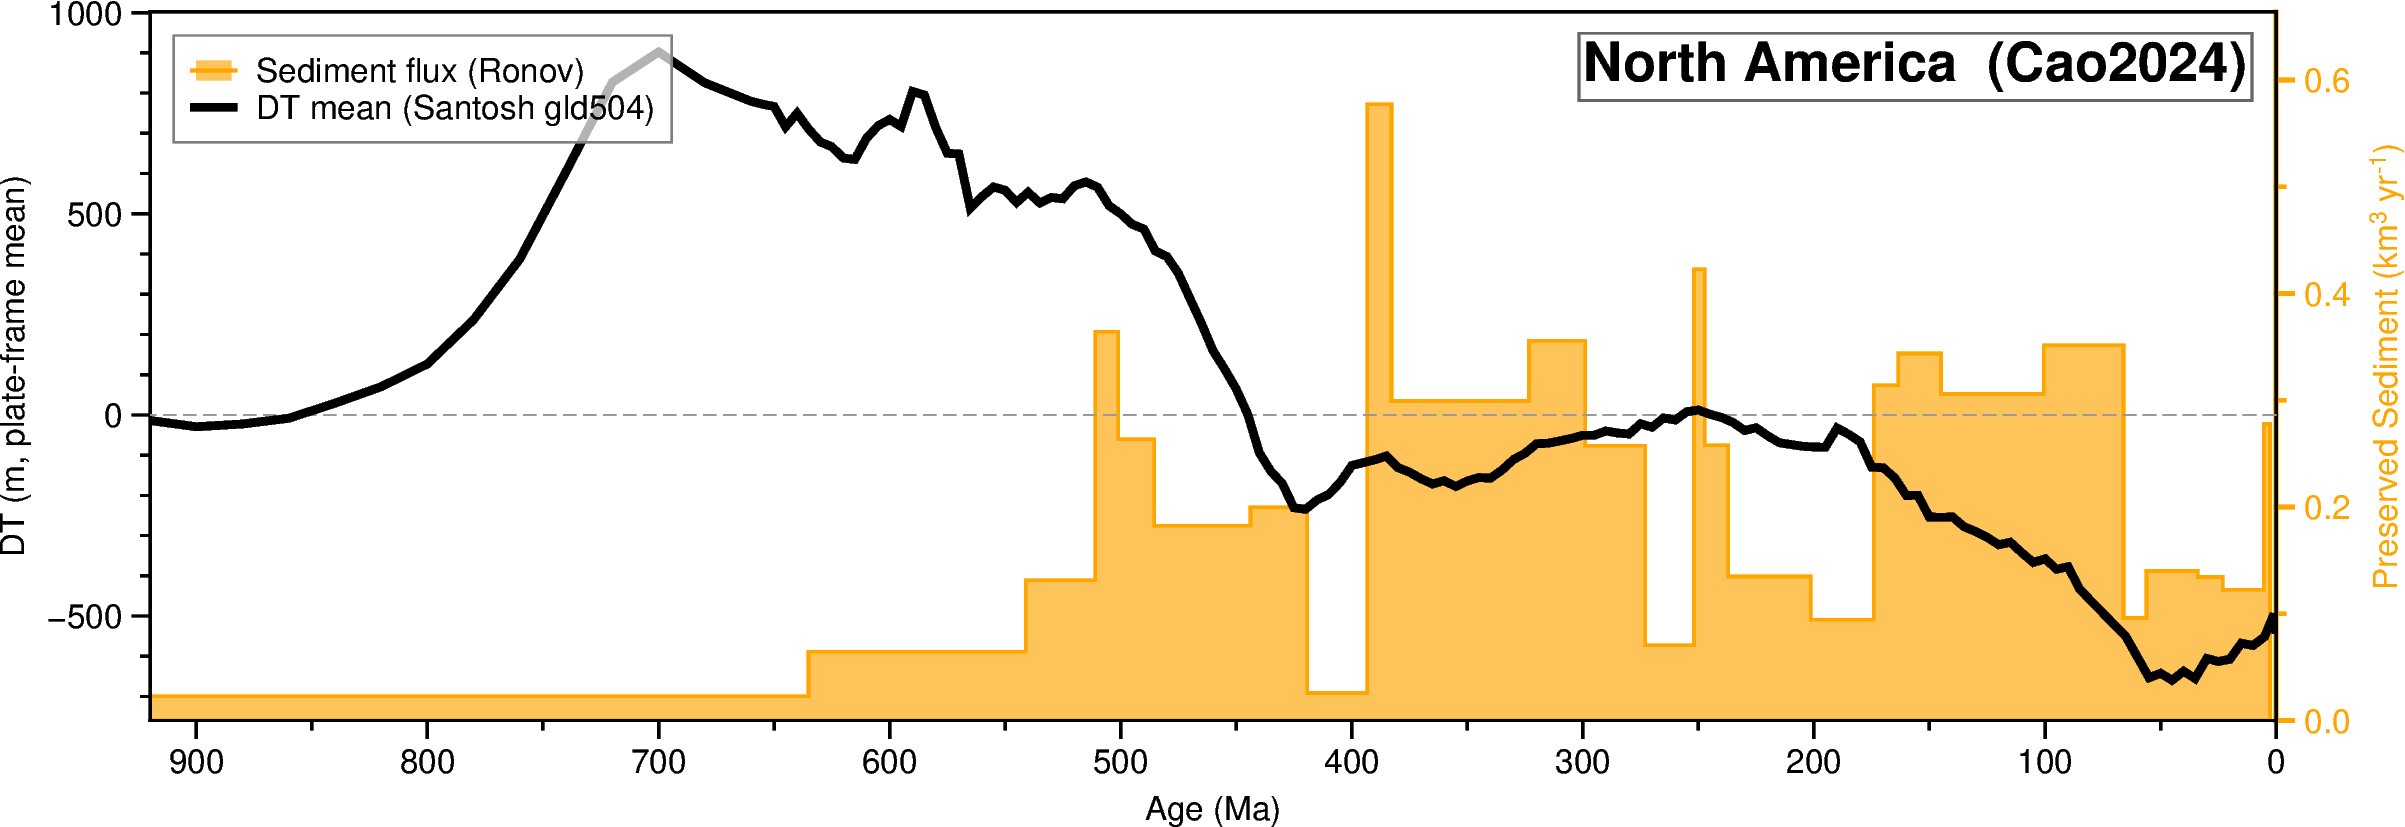

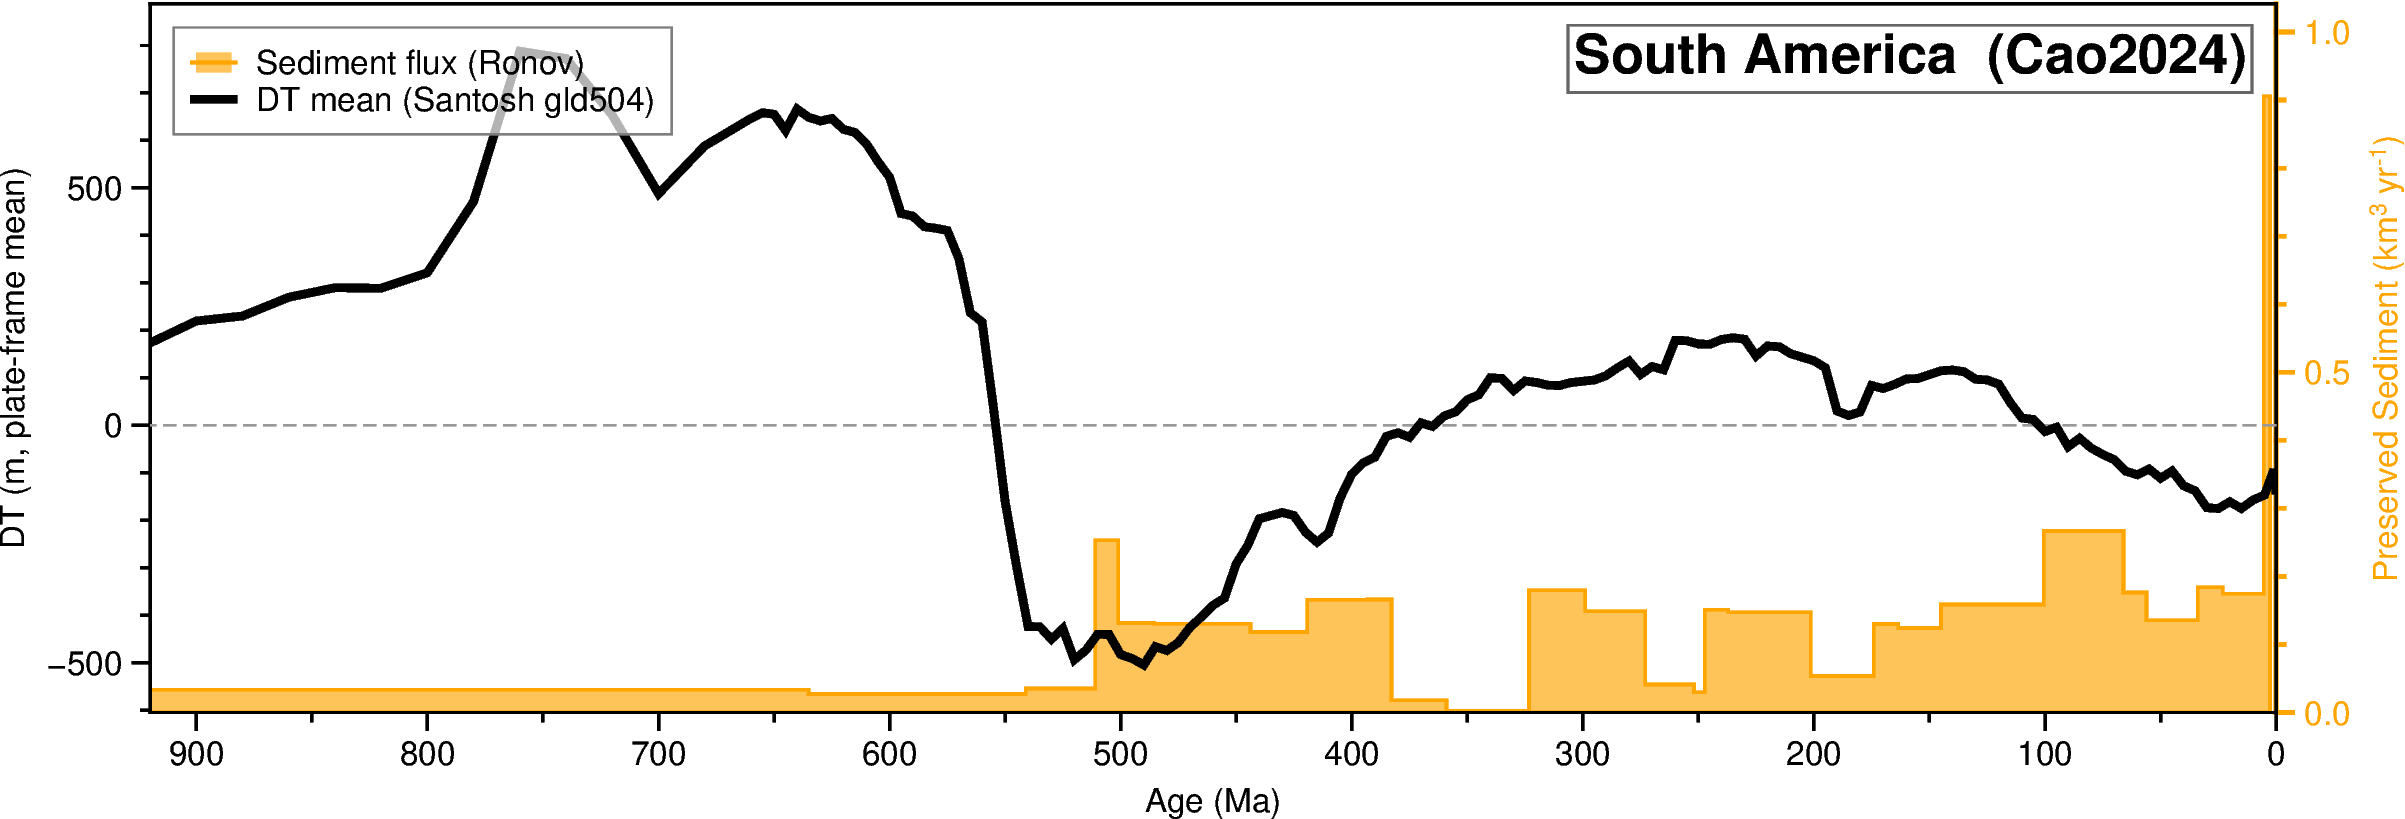

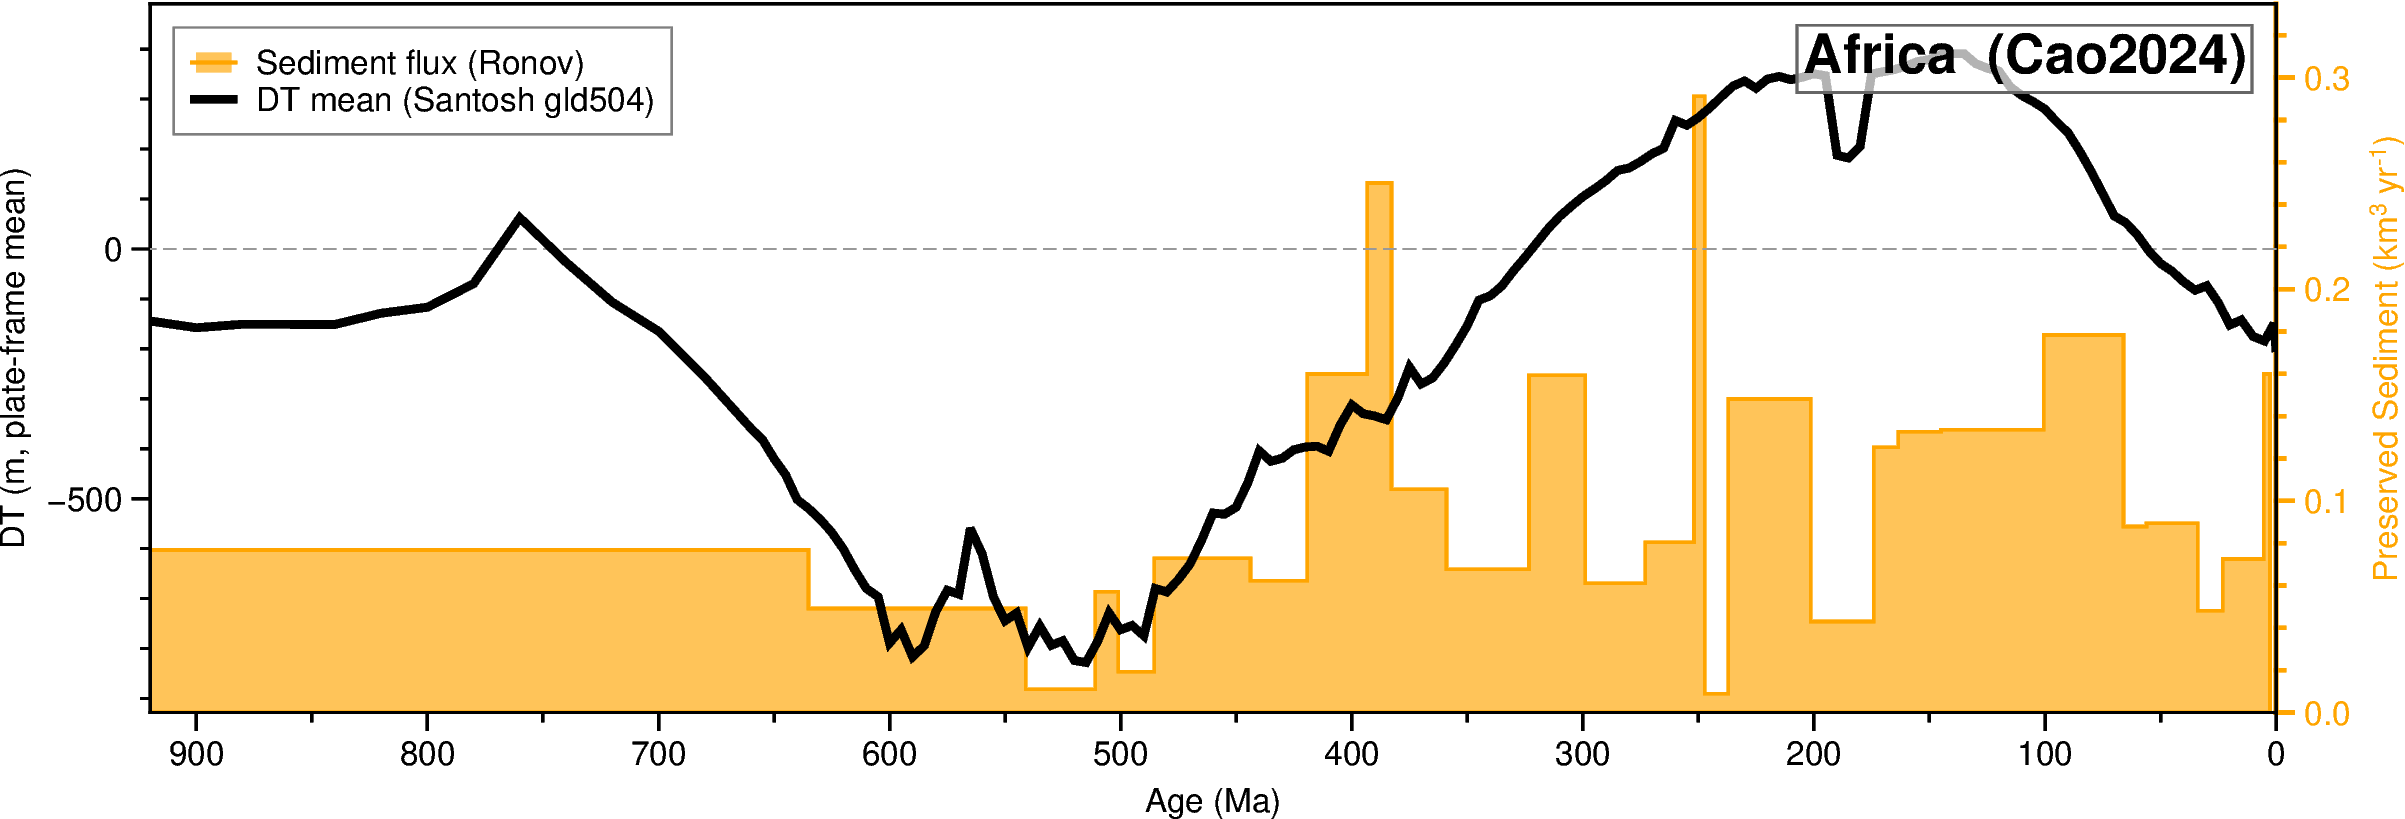

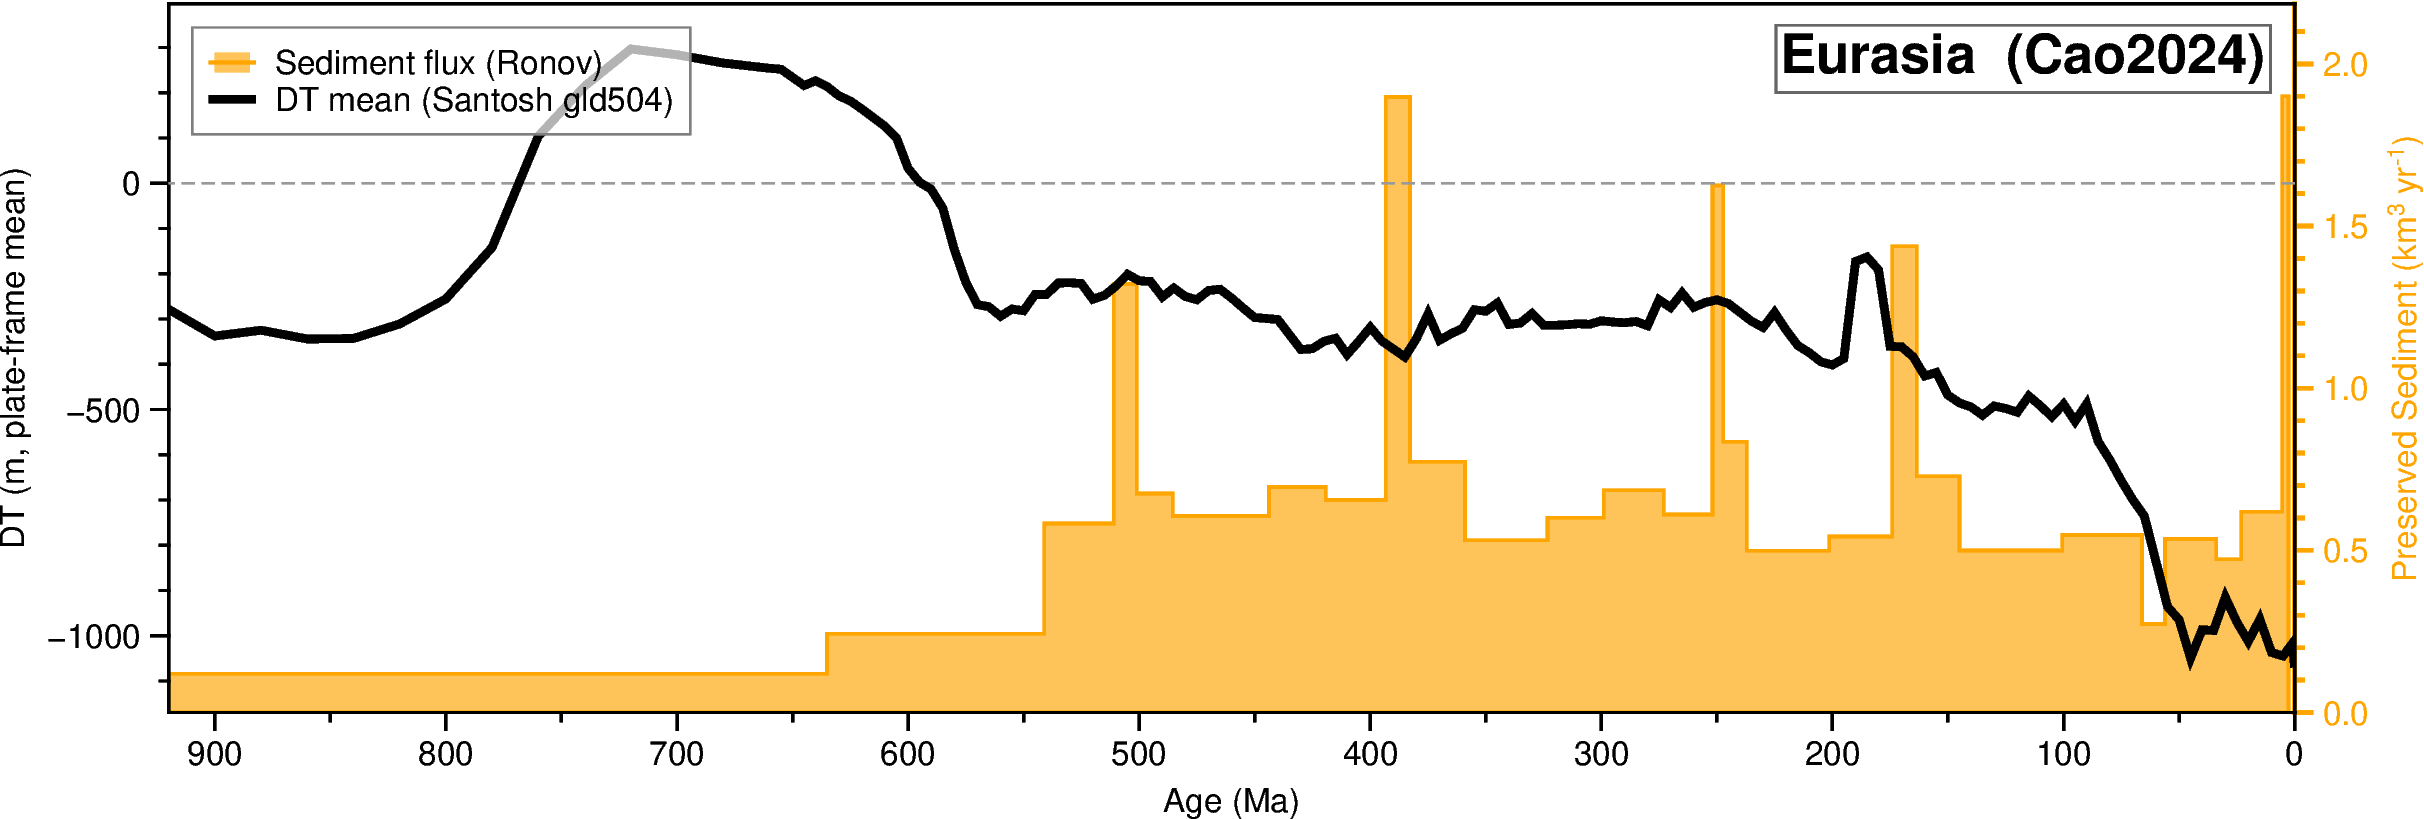

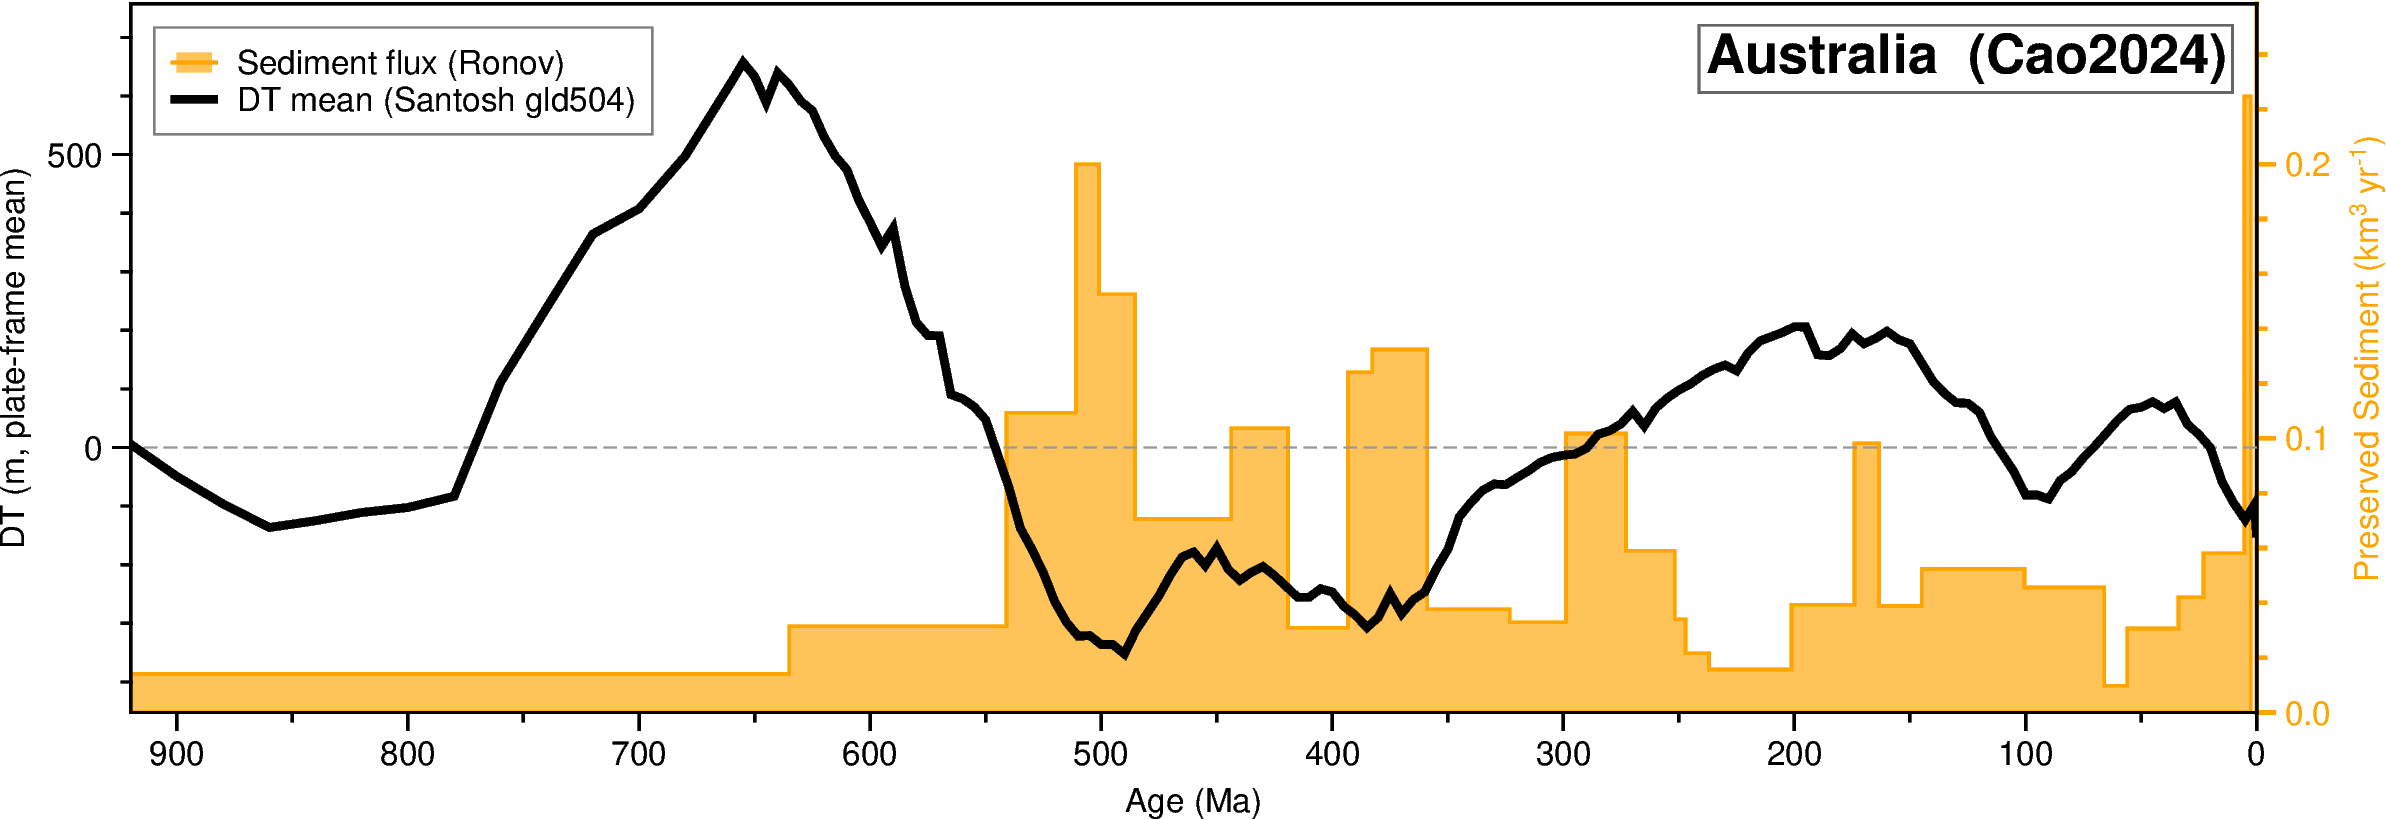

In [5]:
# Cell 4 — per continent: mean dynamic topography (black, left axis) and the
# preserved-sediment rate of Ronov's compilation (orange, right axis).
# One figure per continent (suite house style — no pygmt.subplot).
# Each figure shares the same x range (0-920 Ma) so a vertical line
# at any age compares all continents at once.

X_MIN, X_MAX = 0.0, 920.0
PROJ = "X-18c/6c"
KEY = {"North America": "Ronov_NAm", "South America": "Ronov_SAm",
       "Africa": "Ronov_Afr", "Eurasia": "Ronov_Eur", "Australia": "Ronov_Aus"}

r = sed[(sed["t_age"] > 0) & (sed["t_age"] < X_MAX)].sort_values("t_age")  # rows inside the plotted age range
dt = (r["b_age"] - r["t_age"]).to_numpy(float)    # interval length (Myr) = bottom age - top age
x = np.column_stack([r["t_age"], r["b_age"]]).ravel()          # step edges of the sediment histogram


for name in CONTINENTS:
    times_dt, mean_dt = histories[name]
    y = np.repeat(r[KEY[name]].to_numpy(float) / dt, 2)        # volume per interval / interval length, repeated for the step edges

    fig = pygmt.Figure()
    with pygmt.config(MAP_FRAME_PEN="1p,orange", MAP_TICK_PEN_PRIMARY="1p,orange",
                      FONT_ANNOT_PRIMARY="orange", FONT_LABEL="orange"):
        fig.basemap(region=[X_MIN, X_MAX, 0, y.max() * 1.15], projection=PROJ,
                    frame=["E", "yaf+l Preserved Sediment (km@+3@+ yr@+-1@+)"])
    fig.plot(x=np.r_[x[0], x, x[-1]], y=np.r_[0, y, 0], close=True,
             fill="orange@35", pen="0.8p,orange", label="Sediment flux (Ronov)")

    fig.basemap(region=[X_MIN, X_MAX, np.nanmin(mean_dt) - 100, np.nanmax(mean_dt) + 100],
                projection=PROJ, frame=["xa100f50+lAge (Ma)", "yaf+lDT (m, plate-frame mean)", "WSrt"])
    fig.plot(x=[X_MIN, X_MAX], y=[0, 0], pen="0.4p,gray60,--")
    fig.plot(x=times_dt, y=mean_dt, pen="2p,black", label=f"DT mean (Santosh {GLD_ID})")

    fig.legend(position="JTL+jTL+o0.2c", box="+gwhite@30+p0.5p,gray50")
    fig.text(text=f"{name}  ({MODEL_NAME})", position="TR", offset="-0.25c/-0.25c",
             justify="TR", font="13p,Helvetica-Bold,black", fill="white@30", pen="0.6p,gray40")
    fig.show(width=1000)
    display(HTML('<div style="height:0.6cm"></div>'))

## What the figure shows

One figure per continent (North America, South America, Africa, Eurasia, Australia), all on the same age axis from 0 to 920 Ma with today on the left. The black line is the mean plate-frame dynamic topography of the continent (left axis, metres). The orange steps are Ronov's preserved sediment volume of each age interval divided by the length of the interval (right axis); each step spans one interval of the compilation.

Look for:

- **Falling DT followed by more preserved sediment** — subsidence opens accommodation space, so periods of falling or negative DT should coincide with high preserved-sediment rates. Dhungana & Flament (2026) find prolonged Neoproterozoic uplift followed by long-term Phanerozoic subsidence for Laurentia, the pattern that formed and preserved the Great Unconformity.
- **High DT with little preserved sediment** — uplift exposes the continent to erosion and leaves a gap in the record.
- **The same signal on several continents** — points to a global driver such as sea level rather than continent-scale mantle flow.
- **No relation at all** — on that continent something other than dynamic topography (orogeny, climate, regional tectonics) controls the preserved record.

E04, E06 and E07 compute the DT fields behind these curves in other ways; repeating this comparison with their DT histories tests how robust the match is to the choice of mantle model.

## Extend this

- **Cross-correlate.** Compute lagged correlation between the DT and sediment-flux time series per continent and look for systematic continent-specific lags.
- **Other DT models.** Swap `the PlateFrameGrid_<CONTINENT>/ subdirectories scanned by the loader` for a different mantle-flow simulation and see whether the DT-sediment co-variation is robust to model choice.
- **Cross-reference E03.** E03 shows the *vertical* mantle structure under a transect; E05 shows the *horizontal* time-series at a continent. Together they make the case for the deep-mantle origin of long-term surface signals.

## References

- Dhungana, S. & Flament, N. (2026). The deep Earth origin of the Great Unconformity. *Nature* 659, 106–112. https://doi.org/10.1038/s41586-026-11156-5
- Keller, C.B., Husson, J.M., Mitchell, R.N., Bottke, W.F., Gernon, T.M., Boehnke, P., Bell, E.A., Swanson-Hysell, N.L. & Peters, S.E. (2019). Neoproterozoic glacial origin of the Great Unconformity. *Proceedings of the National Academy of Sciences* 116(4), 1136–1145. https://doi.org/10.1073/pnas.1804350116
- Ronov, A.B. (1994). Phanerozoic transgressions and regressions on the continents. *American Journal of Science* 294, 777–801.
- Mather, B.R., Müller, R.D., Zahirovic, S., Cannon, J., Chin, M., Ilano, L., Wright, N.M., Alfonso, C., Williams, S., Tetley, M. & Merdith, A. (2024). Deep time spatio-temporal data analysis using pyGPlates with PlateTectonicTools and GPlately. *Geoscience Data Journal* 11(1), 3–10. https://doi.org/10.1002/gdj3.185
- Tian, D., Uieda, L., Leong, W.J., Fröhlich, Y., Schlitzer, W., Grund, M., Jones, M., Toney, L., Yao, J., Magen, Y., Tong, J.-H., Ngo, L., Materna, K., Belem, A., Newton, T., Anant, A., Ziebarth, M., Quinn, J. & Wessel, P. (2024). PyGMT: A Python interface for the Generic Mapping Tools. *Zenodo*. https://doi.org/10.5281/zenodo.13679420
- Wessel, P., Luis, J.F., Uieda, L., Scharroo, R., Wobbe, F., Smith, W.H.F. & Tian, D. (2019). The Generic Mapping Tools version 6. *Geochemistry, Geophysics, Geosystems* 20(11), 5556–5564. https://doi.org/10.1029/2019GC008515

- Cao, X., Collins, A.S., Pisarevsky, S., Flament, N., Li, S., Hasterok, D. & Müller, R.D. (2024). Earth's tectonic and plate boundary evolution over 1.8 billion years. *Geoscience Frontiers* 15, 101922. https://doi.org/10.1016/j.gsf.2024.101922
